In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_squared_error

In [2]:
# 2. Load dataset
df = pd.read_csv("uber.csv")
print(df.head())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [17]:
# Remove invalid values
df = df[df['fare_amount'] > 0]
df = df[df['passenger_count'] > 0]

df = df[
    # Check that latitude is within its valid range of -90 to 90 degrees.
    df['pickup_latitude'].between(-90, 90) &
    # Check that latitude is within its valid range of -90 to 90 degrees.
    df['dropoff_latitude'].between(-90, 90) &
    # Check that longitude is within its valid range of -180 to 180 degrees.
    df['pickup_longitude'].between(-180, 180) &
    # Check that longitude is within its valid range of -180 to 180 degrees.
    df['dropoff_longitude'].between(-180, 180)
]

In [4]:
# 4. Remove invalid fare values
df = df[df['fare_amount'] > 0]

# 5. Identify and remove outliers using IQR
# Find the first quartile (25th percentile).
Q1 = df['fare_amount'].quantile(0.25)
# Find the third quartile (75th percentile).
Q3 = df['fare_amount'].quantile(0.75)
# IQR is the spread of the middle 50% of the fare values.
IQR = Q3 - Q1

# The 1.5 × IQR rule defines the lower and upper outlier boundaries.
lower = Q1 - 1.5 * IQR
# The 1.5 × IQR rule defines the lower and upper outlier boundaries.
upper = Q3 + 1.5 * IQR

# The pipe symbol means OR when combining pandas conditions.
print("Outliers:", len(df[(df['fare_amount'] < lower) | (df['fare_amount'] > upper)]))

# The ampersand means AND when combining pandas conditions.
df = df[(df['fare_amount'] >= lower) & (df['fare_amount'] <= upper)]

# 6. Correlation heatmap
# Draw a heatmap so correlations between numeric columns are easier to compare.
sns.heatmap(df.corr(), annot=True)
plt.show()

# 7. Select input and output
# Remove the fare column from inputs because it is the value being predicted.
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

# 8. Split data
X_train, X_test, y_train, y_test = train_test_split(
    # Reserve 20% of the records for testing; the remaining 80% train the model.
    X, y, test_size=0.2, random_state=42
)

# 9. Scale data
sc = StandardScaler()
# Learn scaling values from training data and standardize the training features.
X_train = sc.fit_transform(X_train)
# Apply the training scaling values to test data; do not fit again on test data.
X_test = sc.transform(X_test)

# 10. Linear Regression
m1 = LinearRegression()
m1.fit(X_train, y_train)
p1 = m1.predict(X_test)

# 11. Ridge Regression
# Ridge regression adds an L2 penalty to reduce overly large model coefficients.
m2 = Ridge()
m2.fit(X_train, y_train)
p2 = m2.predict(X_test)

# 12. Lasso Regression
# Lasso regression adds an L1 penalty and can shrink some coefficients to zero.
m3 = Lasso()
m3.fit(X_train, y_train)
p3 = m3.predict(X_test)

# 13. Evaluate models
print("Linear R2:", r2_score(y_test, p1))
# RMSE is the square root of mean squared error; smaller values indicate better predictions.
print("Linear RMSE:", np.sqrt(mean_squared_error(y_test, p1)))

print("Ridge R2:", r2_score(y_test, p2))
# RMSE is the square root of mean squared error; smaller values indicate better predictions.
print("Ridge RMSE:", np.sqrt(mean_squared_error(y_test, p2)))

print("Lasso R2:", r2_score(y_test, p3))
# RMSE is the square root of mean squared error; smaller values indicate better predictions.
print("Lasso RMSE:", np.sqrt(mean_squared_error(y_test, p3)))

# 14. Plot graph
# Each point compares one actual fare with the model's predicted fare.
plt.scatter(y_test, p1)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Uber Fare Prediction")
plt.show()


In [5]:
# 5. Identify and remove outliers using IQR
# Find the first quartile (25th percentile).
Q1 = df['fare_amount'].quantile(0.25)
# Find the third quartile (75th percentile).
Q3 = df['fare_amount'].quantile(0.75)
# IQR is the spread of the middle 50% of the fare values.
IQR = Q3 - Q1

# The 1.5 × IQR rule defines the lower and upper outlier boundaries.
lower = Q1 - 1.5 * IQR
# The 1.5 × IQR rule defines the lower and upper outlier boundaries.
upper = Q3 + 1.5 * IQR

# The pipe symbol means OR when combining pandas conditions.
print("Outliers:", len(df[(df['fare_amount'] < lower) | (df['fare_amount'] > upper)]))

# The ampersand means AND when combining pandas conditions.
df = df[(df['fare_amount'] >= lower) & (df['fare_amount'] <= upper)]

Outliers: 17155


<Axes: >

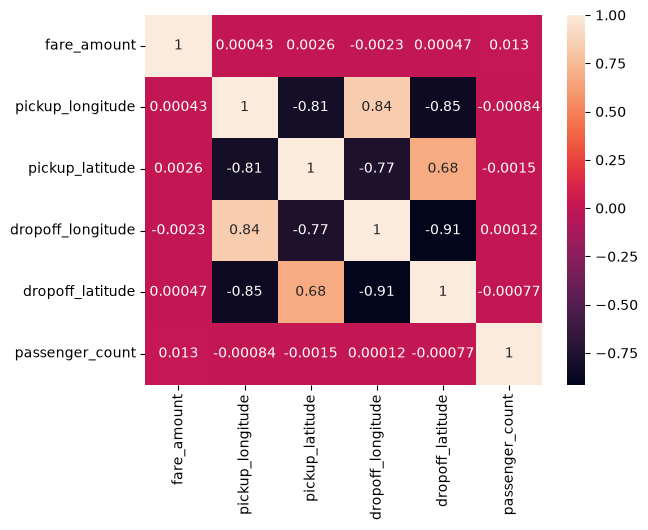

In [16]:
# Visualize correlations between numeric dataset columns.
# Draw a heatmap so correlations between numeric columns are easier to compare.
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [7]:
# 7. Select input and output
# Remove the fare column from inputs because it is the value being predicted.
X = df.drop('fare_amount', axis=1)
y = df['fare_amount']

In [8]:
# 8. Split data
X_train, X_test, y_train, y_test = train_test_split(
    # Reserve 20% of the records for testing; the remaining 80% train the model.
    X, y, test_size=0.2, random_state=42
)

In [9]:
# 9. Scale data
sc = StandardScaler()
# Learn scaling values from training data and standardize the training features.
X_train = sc.fit_transform(X_train)
# Apply the training scaling values to test data; do not fit again on test data.
X_test = sc.transform(X_test)

In [10]:
# 10. Linear Regression
m1 = LinearRegression()
m1.fit(X_train, y_train)
p1 = m1.predict(X_test)

# 11. Ridge Regression
# Ridge regression adds an L2 penalty to reduce overly large model coefficients.
m2 = Ridge()
m2.fit(X_train, y_train)
p2 = m2.predict(X_test)

# 12. Lasso Regression
# Lasso regression adds an L1 penalty and can shrink some coefficients to zero.
m3 = Lasso()
m3.fit(X_train, y_train)
p3 = m3.predict(X_test)

In [11]:
# 13. Evaluate models
print("Linear R2:", r2_score(y_test, p1))
# RMSE is the square root of mean squared error; smaller values indicate better predictions.
print("Linear RMSE:", np.sqrt(mean_squared_error(y_test, p1)))

print("Ridge R2:", r2_score(y_test, p2))
# RMSE is the square root of mean squared error; smaller values indicate better predictions.
print("Ridge RMSE:", np.sqrt(mean_squared_error(y_test, p2)))

print("Lasso R2:", r2_score(y_test, p3))
# RMSE is the square root of mean squared error; smaller values indicate better predictions.
print("Lasso RMSE:", np.sqrt(mean_squared_error(y_test, p3)))

Linear R2: 6.66048690546317e-05
Linear RMSE: 4.175141541376116
Ridge R2: 6.660537707103842e-05
Ridge RMSE: 4.175141540315526
Lasso R2: -0.0001311921424891338
Lasso RMSE: 4.175554463720892


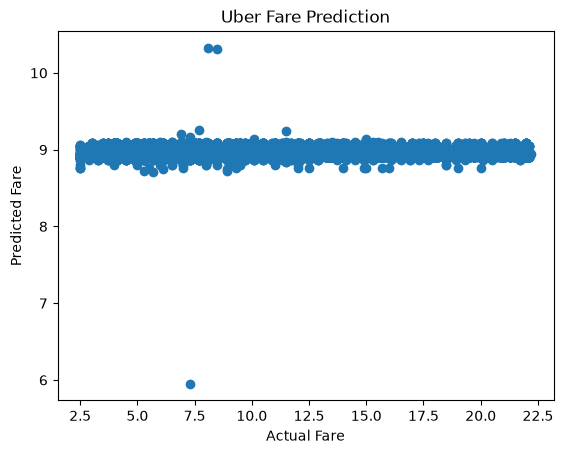

In [12]:
# 14. Plot graph
# Each point compares one actual fare with the model's predicted fare.
plt.scatter(y_test, p1)
plt.xlabel("Actual Fare")
plt.ylabel("Predicted Fare")
plt.title("Uber Fare Prediction")
plt.show()
